# Black–Scholes and Monte-Carlo pricing

Closed-form European call price under Black–Scholes, compared against a
Monte-Carlo pricer that simulates 50 000 terminal stock prices under
geometric Brownian motion.

In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

np.random.seed(0)

## 1. Closed-form Black–Scholes call

For a European call with spot $S_0$, strike $K$, maturity $T$, risk-free
rate $r$, and volatility $\sigma$:

$$C = S_0 \Phi(d_1) - K e^{-rT} \Phi(d_2), \quad
  d_{1,2} = \frac{\ln(S_0/K) + (r \pm \tfrac{1}{2}\sigma^2) T}{\sigma \sqrt{T}}.$$

In [2]:
def bs_call(S0, K, T, r, sigma):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.20
price_bs = bs_call(S0, K, T, r, sigma)
print(f"Black-Scholes call price: {price_bs:.4f}")

Black-Scholes call price: 10.4506


## 2. Monte-Carlo pricer

Simulate terminal prices $S_T = S_0 \exp\left((r - \tfrac{1}{2}\sigma^2) T +
\sigma \sqrt{T}\, Z\right)$ with $Z \sim \mathcal{N}(0, 1)$, then discount
the mean payoff. 50 000 paths.

In [3]:
n_paths = 50_000
Z = np.random.standard_normal(n_paths)
ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
payoff = np.maximum(ST - K, 0.0)
price_mc = np.exp(-r * T) * payoff.mean()
stderr = np.exp(-r * T) * payoff.std(ddof=1) / np.sqrt(n_paths)

print(f"Monte-Carlo price:        {price_mc:.4f}  (95% CI half-width {1.96*stderr:.4f})")
print(f"Black-Scholes price:      {price_bs:.4f}")
print(f"Absolute error:           {abs(price_mc - price_bs):.4f}")

Monte-Carlo price:        10.3501  (95% CI half-width 0.1279)
Black-Scholes price:      10.4506
Absolute error:           0.1005


## 3. Distribution of terminal prices

Under GBM, $\log S_T$ is normal, so $S_T$ is lognormal.

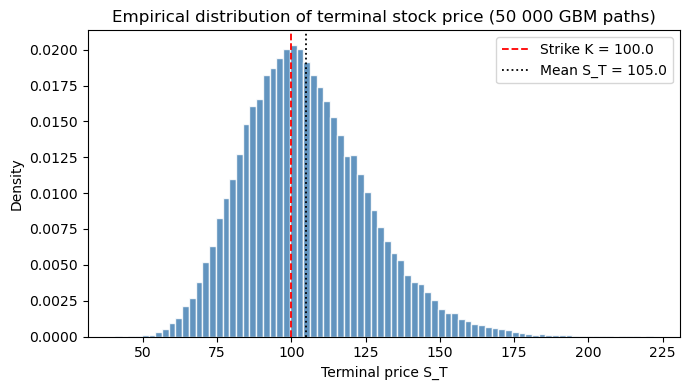

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ST, bins=80, density=True, color="steelblue", edgecolor="white", alpha=0.85)
ax.axvline(K, color="red", ls="--", lw=1.3, label=f"Strike K = {K}")
ax.axvline(ST.mean(), color="black", ls=":", lw=1.3, label=f"Mean S_T = {ST.mean():.1f}")
ax.set_xlabel("Terminal price S_T")
ax.set_ylabel("Density")
ax.set_title("Empirical distribution of terminal stock price (50 000 GBM paths)")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Convergence of MC estimator

The MC error shrinks as $1/\sqrt{N}$. Plot absolute error vs number of paths.

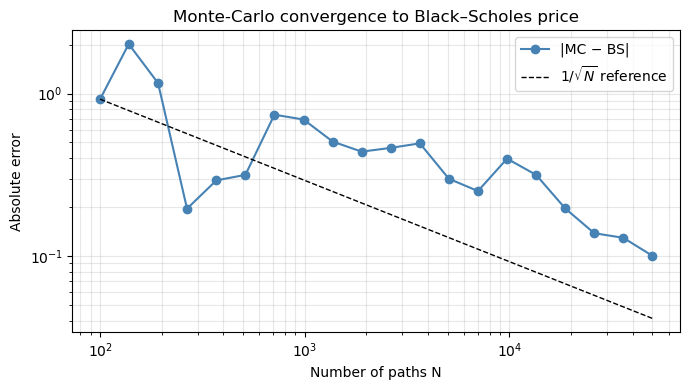

In [5]:
ns = np.logspace(2, np.log10(n_paths), 20).astype(int)
errs = []
for n in ns:
    est = np.exp(-r * T) * np.maximum(ST[:n] - K, 0.0).mean()
    errs.append(abs(est - price_bs))

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(ns, errs, "o-", color="steelblue", label="|MC − BS|")
ax.loglog(ns, errs[0] * np.sqrt(ns[0] / ns), "k--", lw=1, label="$1/\\sqrt{N}$ reference")
ax.set_xlabel("Number of paths N")
ax.set_ylabel("Absolute error")
ax.set_title("Monte-Carlo convergence to Black–Scholes price")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## Exercises

1. Extend the MC pricer to a European **put** and verify put-call parity
   $C - P = S_0 - K e^{-rT}$.
2. Implement antithetic variates (use both $Z$ and $-Z$) and measure the
   variance reduction at fixed $N$.
3. Price a path-dependent Asian call (payoff based on the arithmetic mean
   of $S$ sampled at monthly intervals) using MC. No closed form exists —
   this is where MC earns its keep.